# Time lag checks L0 fluxes IRGA72 (2016-2026.09)

</br>

# Imports

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
from datetime import datetime
import pandas as pd
from diive.analysis import Histogram
from diive.plotting import HeatmapDateTime
from diive.core.io.files import load_parquet
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
from diive.core.plotting.plotfuncs import default_format

</br>

# Load data

In [2]:
# The merged Level-0 record written by 01_IRGA72-L0_merge_output_to_parquet_2016-2026.09. It lives in
# the external (untracked) data folder and is addressed by absolute path, so this notebook does not
# depend on the working directory.
SOURCEPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
              r"\workflow\00_L0_CHECKS\IRGA72"
              r"\01_OPENLAG_EDDYPRO_FLUXNET_OUTPUT_IRGA72_2016-2026.09.parquet")
df = load_parquet(filepath=SOURCEPATH)
df

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\00_L0_checks\IRGA
72\01_OPENLAG_EDDYPRO_FLUXNET_OUTPUT_IRGA72_2016-2026.09.parquet (7.051 seconds).

,AIR_MV,AIR_DENSITY,AIR_RHO_CP,AIR_CP,AOA_METHOD,AXES_ROTATION_METHOD,BOWEN,BURBA_METHOD,BADM_LOCATION_LAT,BADM_LOCATION_LONG,...,W_VM97_TEST,W_LGD,W_KID,W_ZCD,W_ITC,W_ITC_TEST,WBOOST_APPLIED,WPL_APPLIED,ZL,ZL_UNCORR
TIMESTAMP_MIDDLE,,,,,,,,,,,,,,,,,,,,,
2016-01-11 15:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-11 15:45:00,0.025415,1.13966,1145.77,1005.36,0.0,1.0,NaN,0.0,47.4783,8.36439,...,801010000.0,1.50,7.65689,0.0,4.0,1.0,0.0,0.0,0.009173,0.009198
2016-01-11 16:15:00,0.025509,1.13546,1141.57,1005.38,0.0,1.0,NaN,0.0,47.4783,8.36439,...,801010000.0,1.55,7.31186,0.0,6.0,1.0,0.0,0.0,0.008916,0.008932
2016-01-11 16:45:00,0.025582,1.13222,1138.33,1005.40,0.0,1.0,NaN,0.0,47.4783,8.36439,...,800010000.0,0.10,8.96945,1.0,7.0,1.0,0.0,0.0,-0.024976,-0.025218
2016-01-11 17:15:00,0.025625,1.13030,1136.42,1005.41,0.0,1.0,NaN,0.0,47.4783,8.36439,...,800010000.0,0.80,7.41958,0.0,9.0,1.0,0.0,0.0,-0.000850,-0.000857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-30 22:45:00,0.026234,1.10322,1117.43,1012.88,0.0,1.0,-0.957786,0.0,47.4783,8.36439,...,800000001.0,0.00,11.26300,135.0,114.0,6.0,0.0,0.0,5.071090,4.745320
2026-09-30 23:15:00,0.026184,1.10528,1119.73,1013.07,0.0,1.0,-2.708120,0.0,47.4783,8.36439,...,800000000.0,0.00,9.37124,40.0,10.0,1.0,0.0,0.0,0.135853,0.133398
2026-09-30 23:45:00,0.026189,1.10510,1119.42,1012.96,0.0,1.0,-1.370940,0.0,47.4783,8.36439,...,800000000.0,0.00,12.06760,48.0,22.0,2.0,0.0,0.0,0.228422,0.218843


In [3]:
tlag_actual_cols = [c for c in df.columns if c.endswith("_TLAG_ACTUAL")]
tlag_actual_cols

['CO2_TLAG_ACTUAL', 'CH4_TLAG_ACTUAL', 'H2O_TLAG_ACTUAL', 'NONE_TLAG_ACTUAL']

In [4]:
# # Time range
# # locs = (df.index.year == 2019) & (df.index.month >= 5)
# locs = df.index.year == 2021
# # locs = (df.index.year == 2017) | (df.index.year == 2018)
# # locs = (df.index.year == 2017) & (df.index < "2017-03-15 23:59:00")
# # locs = (df.index.year == 2019) & ((df.index > "2019-02-17 23:59:00") & (df.index <= "2019-04-30 23:59:00"))
# # locs = (
# #         ((df.index > "2019-01-01 23:59:00") & (df.index < "2019-02-18 07:00:00")) |
# #         ((df.index > "2019-05-01 07:00:00") & (df.index < "2019-05-22 07:00:00"))
# # )
# # locs = (df.index > "2020-02-28 23:59:00") & (df.index < "2020-05-13 07:00:00")
# # locs = (df.index > "2021-07-23 23:59:00")

# tlag_actual = df[tlag_actual_cols][locs].copy()
# first_date = tlag_actual.index[0].date()
# last_date = tlag_actual.index[-1].date()

</br>

# Function for plotting time lags and ranges

In [5]:
def timelags(gascol: str, series: pd.Series, vline1: float, vline2: float, startbin: float, endbin: float):
    # Calculate histogram
    hist = Histogram(
        series=series,
        method='uniques',
        # n_bins=10,
        # ignore_fringe_bins=None
        ignore_fringe_bins=[5, 10]
    )
    results = hist.results
    peakbins = hist.peakbins
    peak = peakbins[0]

    # Restrict shown results
    locs = (results['BIN_START_INCL'] >= startbin) & (results['BIN_START_INCL'] <= endbin)
    results = results[locs].copy()
    hist_bins = results['BIN_START_INCL'].copy()
    hist_counts = results['COUNTS'].copy()

    # Plot
    fig = plt.figure(layout="constrained", facecolor='white', figsize=(21, 8), dpi=72)
    gs = gridspec.GridSpec(1, 1)  # rows, cols
    gs.update(wspace=0.3, hspace=0.3, left=0.03, right=0.97, top=0.97, bottom=0.03)    
    gs = gridspec.GridSpec(2, 1, figure=fig)  # rows, cols
    ax = fig.add_subplot(gs[0, :])
    ax2 = fig.add_subplot(gs[1, :])
    bar_width = .05
    # bar_width = (hist_bins[1] - hist_bins[0]) * 1  # Calculate bar width
    args = dict(width=bar_width, align='edge')
    
    # Axis 1: histogram plot
    ax.bar(x=hist_bins, height=hist_counts, label='counts', zorder=90, color='#78909c', **args)
    title = f"{gascol} (between {first_date} and {last_date})"
    ax.set_title(title, fontsize=24, weight='bold') 
    default_format(ax=ax, ax_xlabel_txt="lag (seconds)", ax_ylabel_txt="counts")
    ax.axvline(peak, color="black")
    ax.axvline(vline1, color="blue")
    ax.axvline(vline2, color="red")
    ax.locator_params(axis='both', nbins=20)
    trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
    ax.text(peak, 0.98, f"PEAK {peak}s",
            size=16, color='black', backgroundcolor='none', transform=trans,
            alpha=1, horizontalalignment='center', verticalalignment='top', zorder=999)
    trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
    ax.text(vline1, 0.70, f"start {vline1}s",
            size=16, color='blue', backgroundcolor='none', transform=trans,
            alpha=1, horizontalalignment='right', verticalalignment='top', zorder=999)
    ax.text(vline2, 0.70, f"end {vline2}s",
            size=16, color='red', backgroundcolor='none', transform=trans,
            alpha=1, horizontalalignment='left', verticalalignment='top', zorder=999)

    # Axis 2: time series
    ax2.plot(series.index, series, alpha=0.5, c='#5f87ae', marker='.', ms=5, ls='solid', lw=1)    
    ax2.axhline(peak, color="black")
    ax2.axhline(vline1, color="blue")
    ax2.axhline(vline2, color="red")
    ax2.locator_params(axis='both', nbins=20)
    default_format(ax=ax2, ax_xlabel_txt="date", ax_ylabel_txt="lag (s)")      
    ax2.set_ylim([hist_bins.iloc[0], hist_bins.iloc[-1]])  # Use same scaling as for ax
    
    fig.show()

</br>

</br>

# Time lags from OPENLAG runs

## 2016_2
*Faulty data after 1 Mar 2016*

In [6]:
locs = (df.index > "2016-01-11 15:05:00") & (df.index <= "2016-03-01 01:00:00")
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

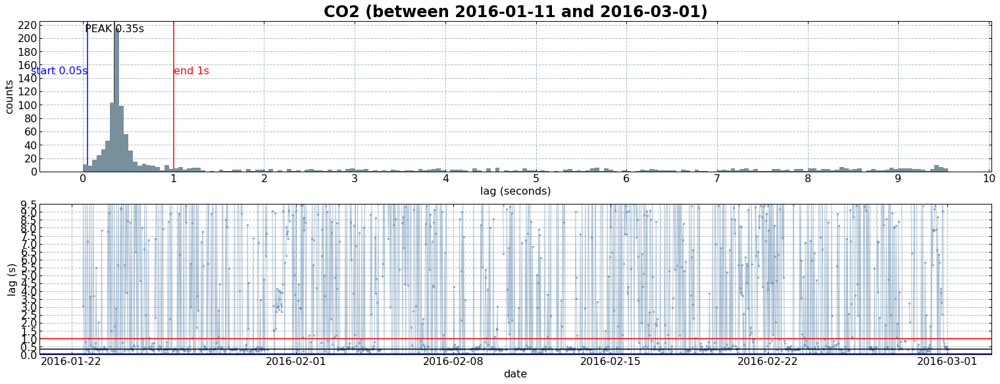

In [7]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.05, vline2=1, startbin=0, endbin=10)

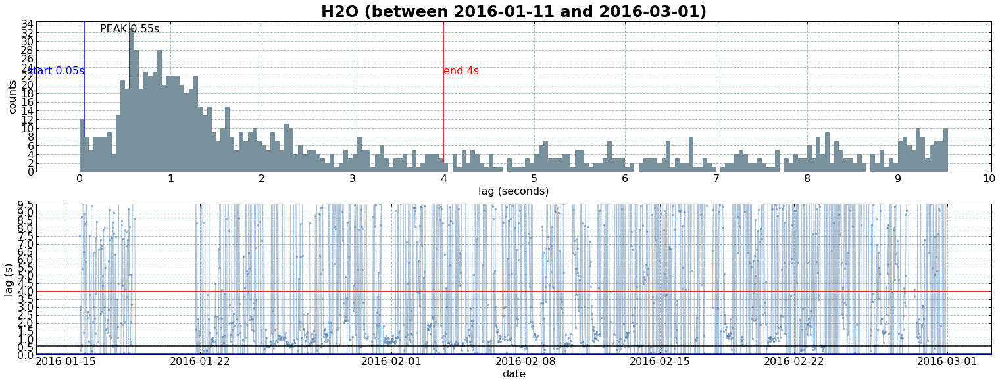

In [8]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0.05, vline2=4, startbin=0, endbin=10)

## 2016_3

In [9]:
locs = (df.index > "2016-05-26 07:00:00") & (df.index <= "2016-12-31 19:00:00")
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

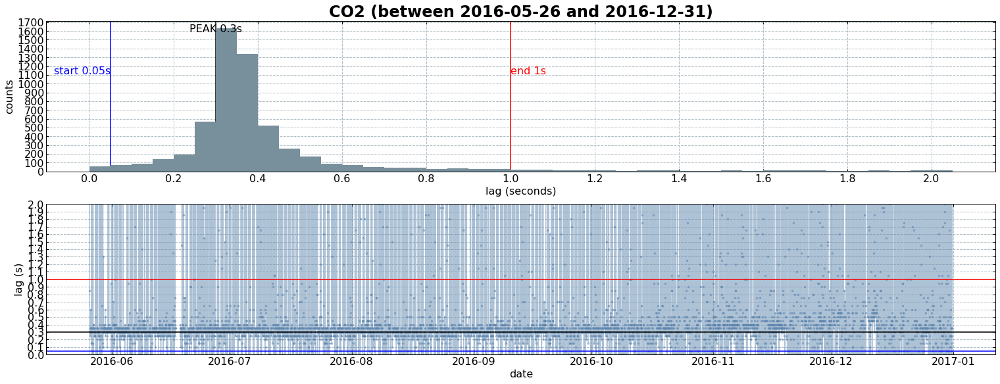

In [10]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.05, vline2=1, startbin=0, endbin=2)

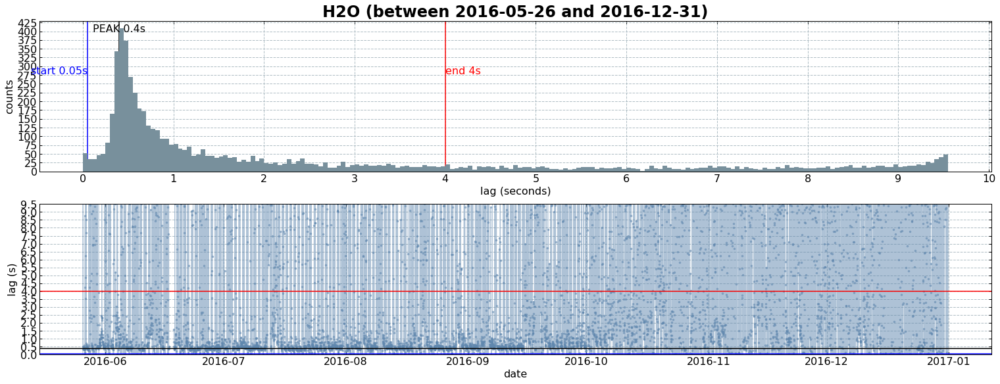

In [11]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0.05, vline2=4, startbin=0, endbin=10)

## 2017_1+2

In [12]:
locs = df.index.year == 2017
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

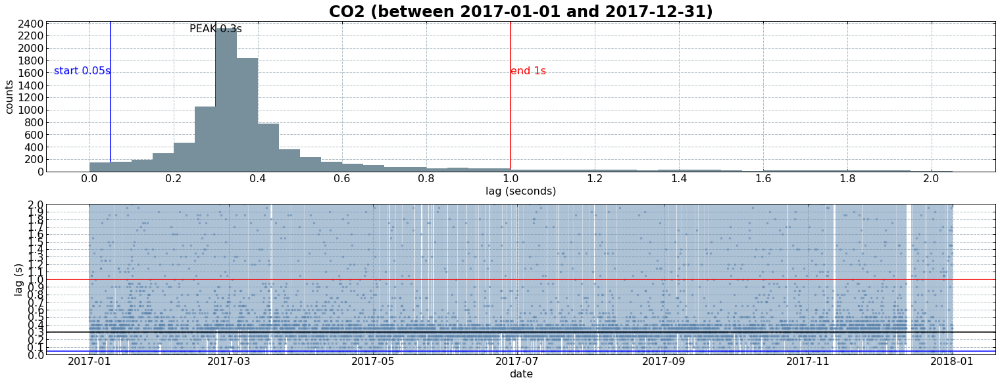

In [13]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.05, vline2=1, startbin=0, endbin=2)

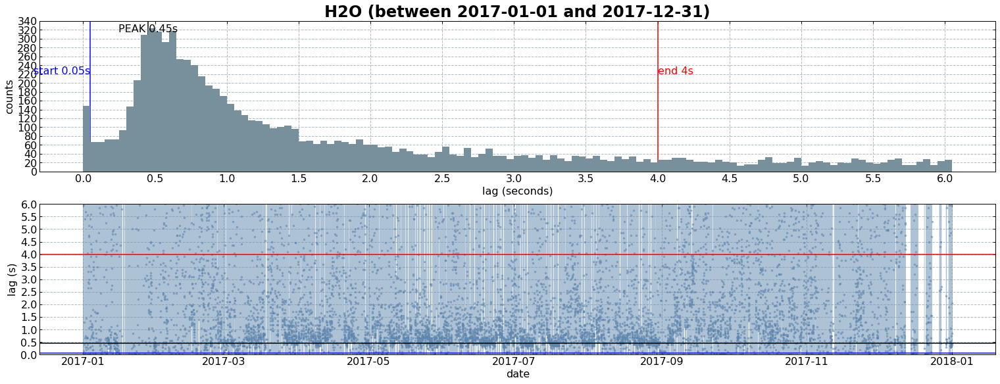

In [14]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0.05, vline2=4, startbin=0, endbin=6)

## 2018_1

In [15]:
locs = (df.index > "2018-01-01 00:28:00") & (df.index <= "2018-01-31 19:00:00")
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

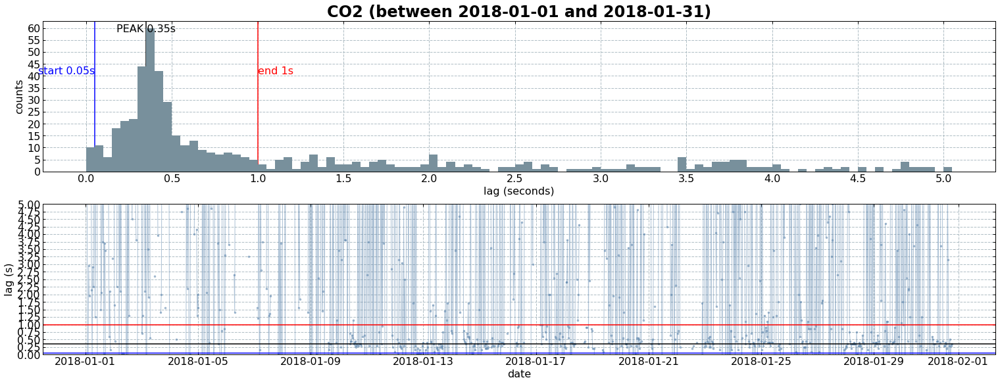

In [16]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.05, vline2=1, startbin=0, endbin=5)

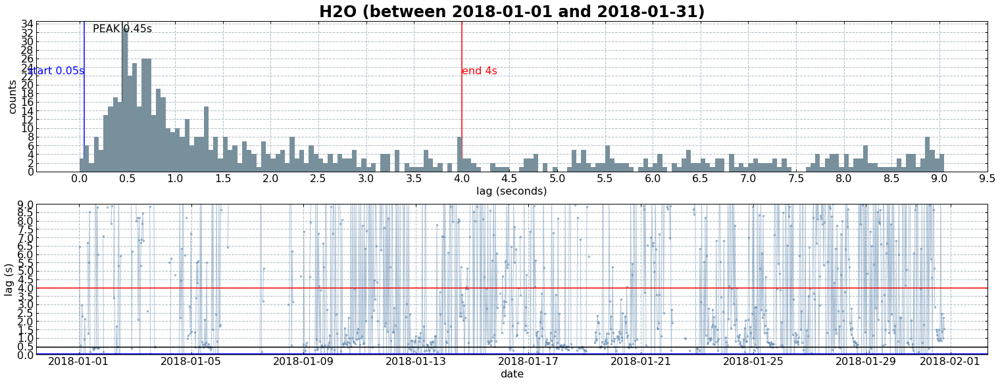

In [17]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0.05, vline2=4, startbin=0, endbin=9)

## 2018_2

In [18]:
locs = (df.index > "2018-01-31 11:28:00") & (df.index <= "2018-05-18 19:00:00")
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

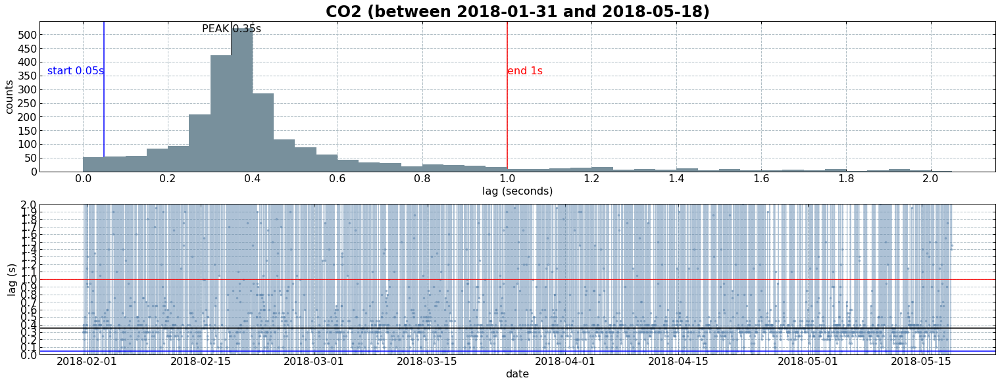

In [19]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.05, vline2=1, startbin=0, endbin=2)

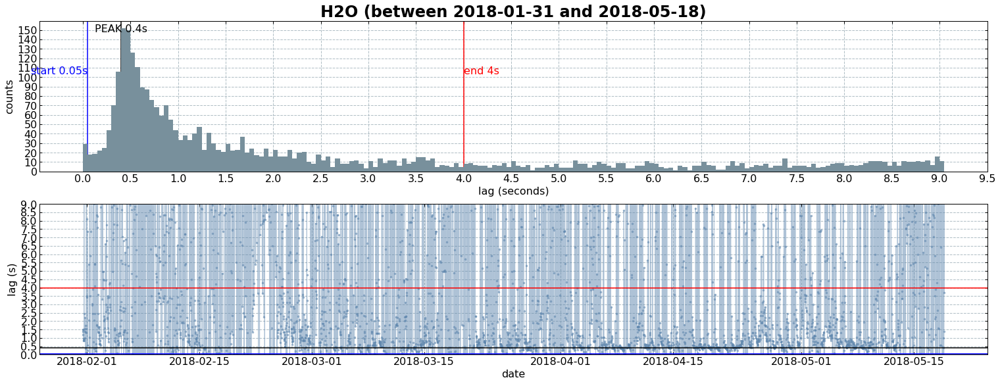

In [20]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0.05, vline2=4, startbin=0, endbin=9)

## 2018_3
*Very low flowrate, unclear time lag, CO2 and H2O fluxes cannot be used*

In [21]:
locs = (df.index > "2018-05-19 00:01:00") & (df.index <= "2018-06-07 19:00:00")
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

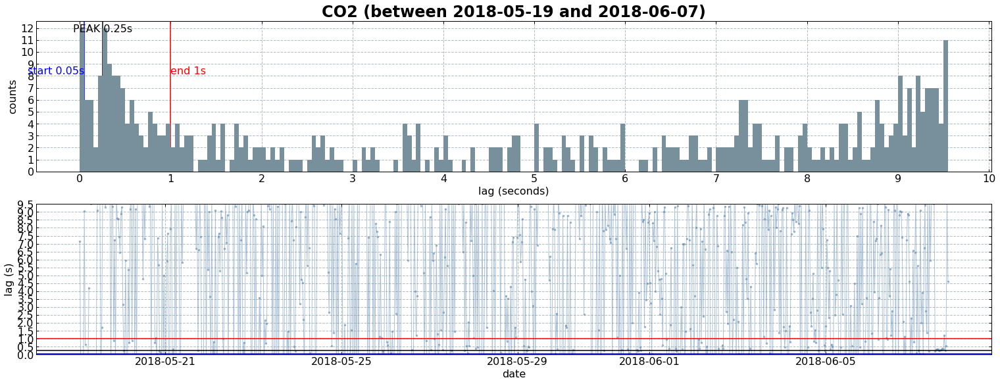

In [22]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.05, vline2=1, startbin=0, endbin=10)

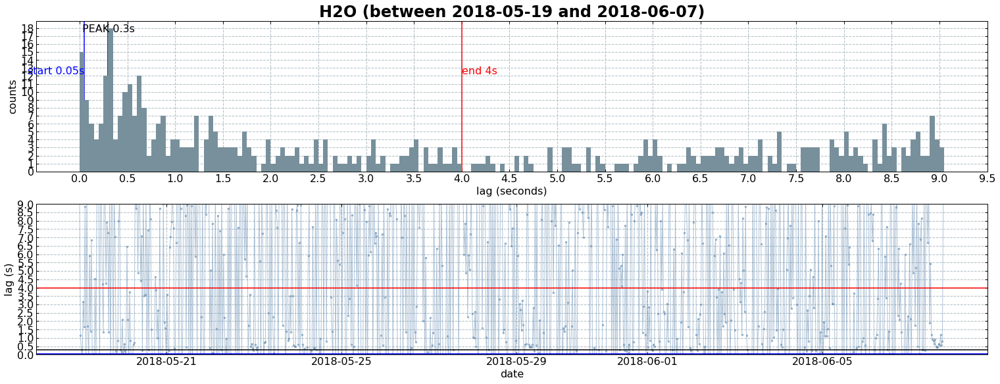

In [23]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0.05, vline2=4, startbin=0, endbin=9)

## 2018_4+2019_1

In [24]:
locs = (df.index > "2018-06-07 13:00:00") & (df.index <= "2019-01-10 13:00:00")
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

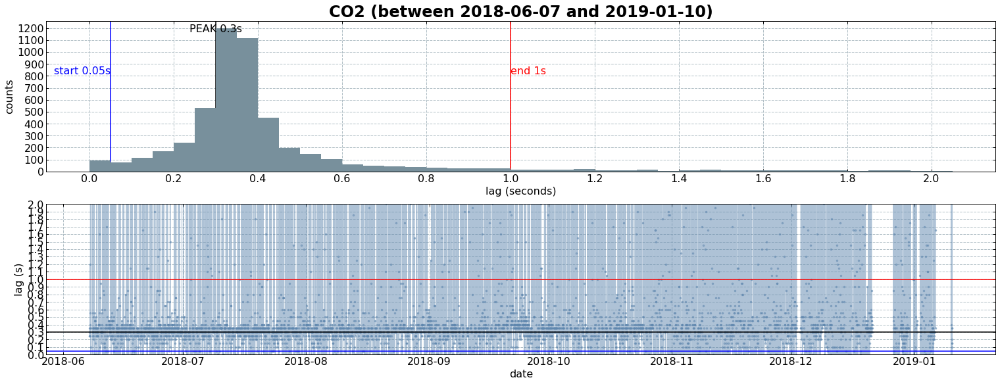

In [25]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.05, vline2=1, startbin=0, endbin=2)

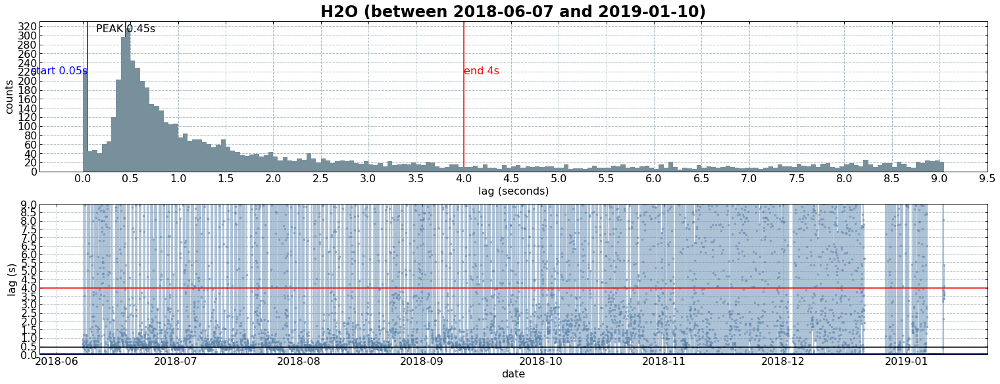

In [26]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0.05, vline2=4, startbin=0, endbin=9)

## 2019_2
*Few data records, files incomplete, IRGA data missing, transition period to files with artifical time lag*

In [27]:
# locs = (df.index > "2019-01-10 15:54:00") & (df.index <= "2019-01-17 07:00:00")
# tlag_actual = df[tlag_actual_cols][locs].copy()
# first_date = tlag_actual.index[0].date()
# last_date = tlag_actual.index[-1].date()

In [28]:
# timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=0, endbin=20)

In [29]:
# timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=7.75, vline2=13, startbin=0, endbin=20)

## 2019_4

In [30]:
locs = (df.index.year == 2019) & ((df.index > "2019-03-20 00:00:00"))
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

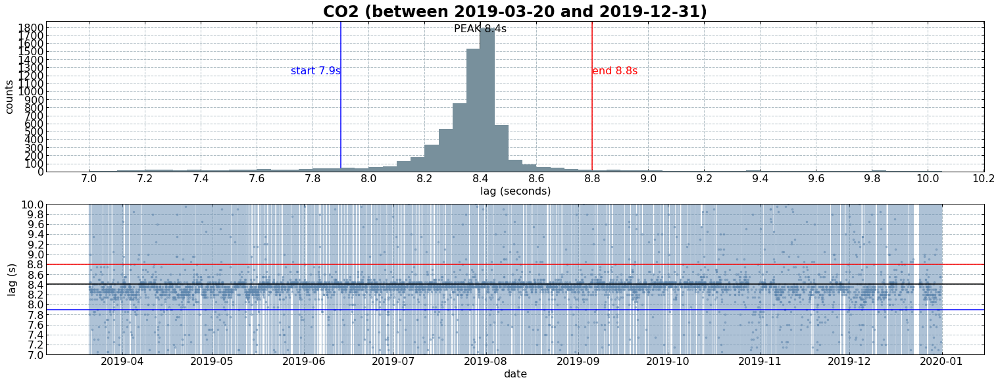

In [31]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=7, endbin=10)

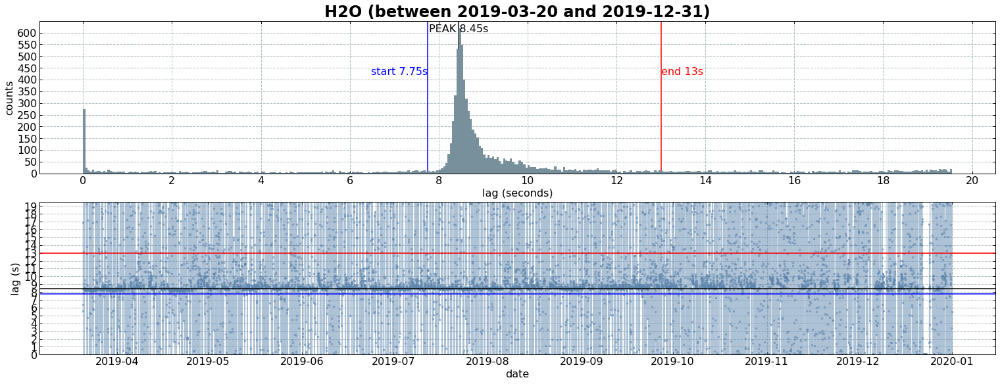

In [32]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=7.75, vline2=13, startbin=0, endbin=20)

## 2020_1

In [33]:
locs = df.index.year == 2020
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

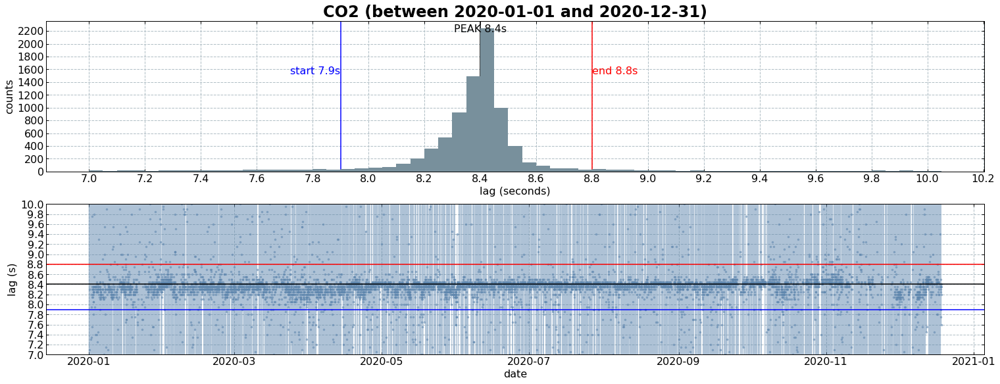

In [34]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=7, endbin=10)

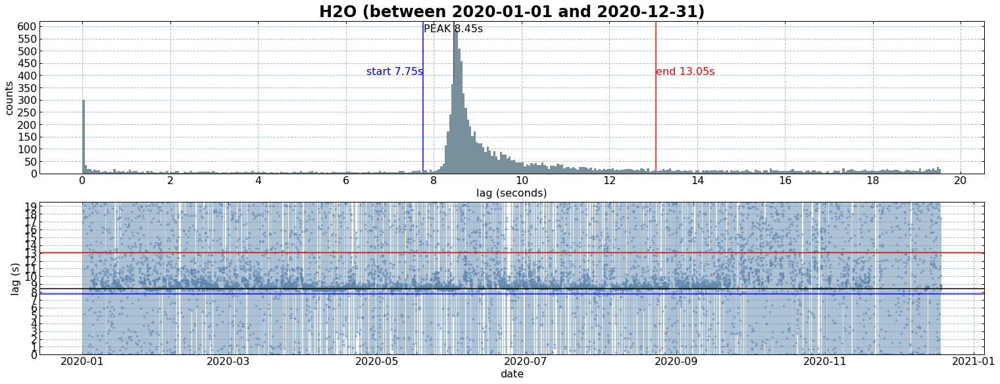

In [35]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=7.75, vline2=13.05, startbin=0, endbin=20)

## 2021_1+2

In [36]:
locs = df.index.year == 2021
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

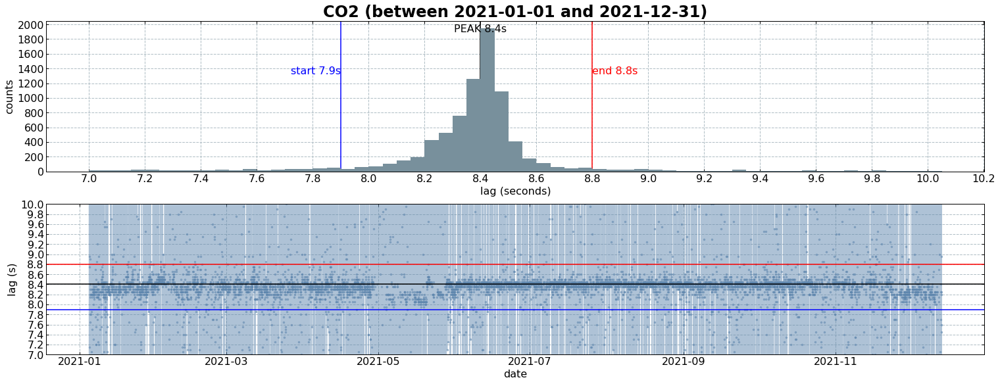

In [37]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=7, endbin=10)

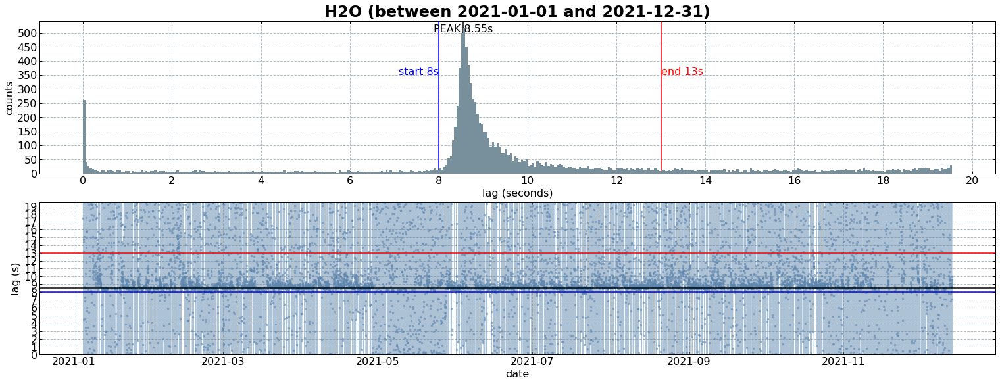

In [38]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=8, vline2=13, startbin=0, endbin=20)

## 2022_1+2+3+4

- 2022_1 not usable

### Complete year

In [39]:
locs = (df.index.year == 2022)
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

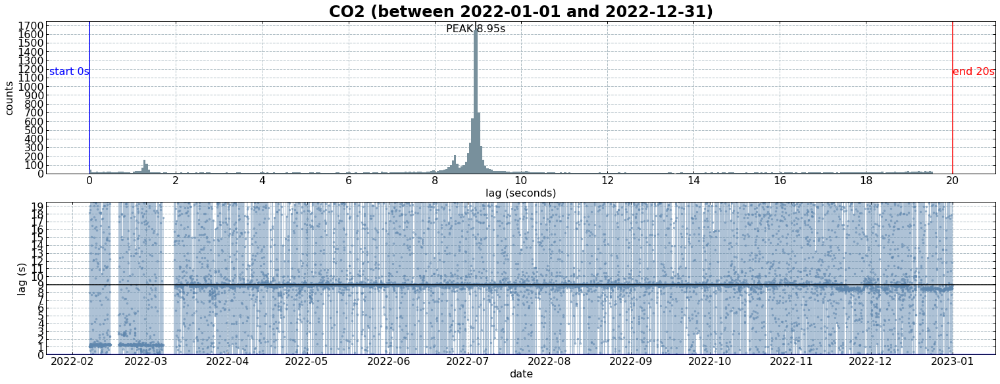

In [40]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0, vline2=20, startbin=0, endbin=20)

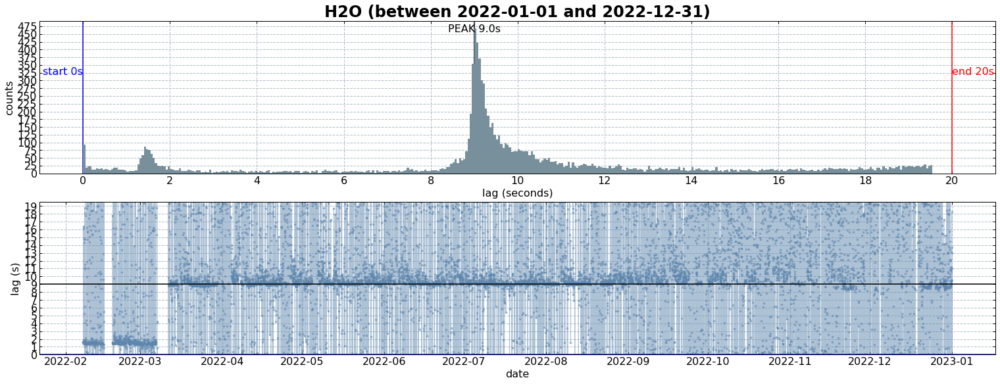

In [41]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=0, vline2=20, startbin=0, endbin=20)

### 2022_2

In [42]:
locs = (df.index.year == 2022) & ((df.index > "2022-02-07 10:58:00") & (df.index <= "2022-03-09 10:26:00"))
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

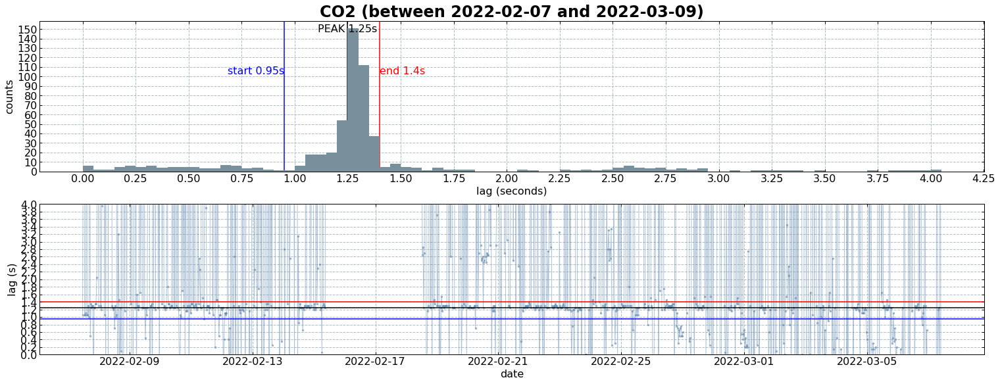

In [43]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=0.95, vline2=1.4, startbin=0, endbin=4)

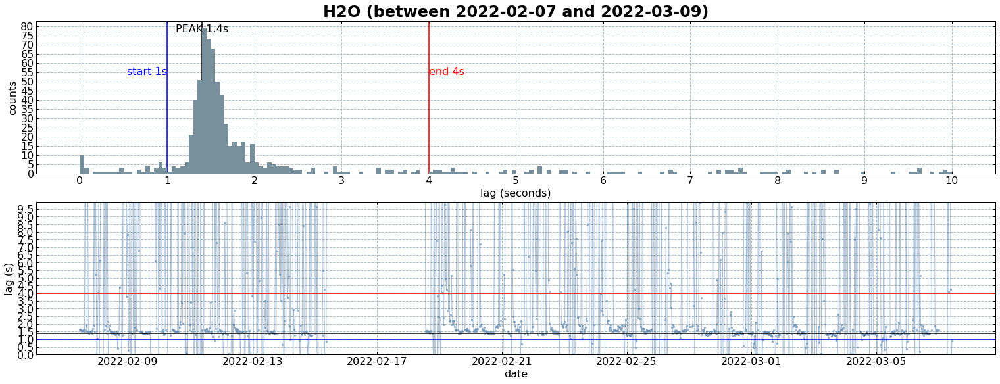

In [44]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=1, vline2=4, startbin=0, endbin=10)

### 2022_3

In [45]:
locs = (df.index.year == 2022) & ((df.index > "2022-03-09 11:00:00") & (df.index <= "2022-11-18 01:00:00"))
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

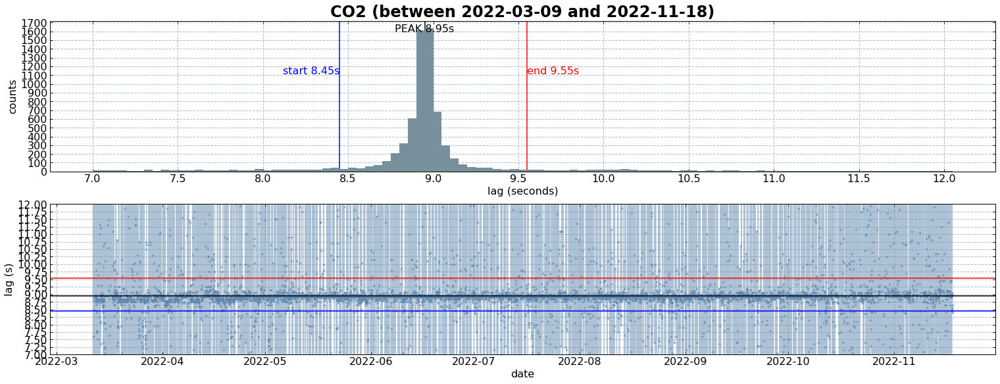

In [46]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=8.45, vline2=9.55, startbin=7, endbin=12)

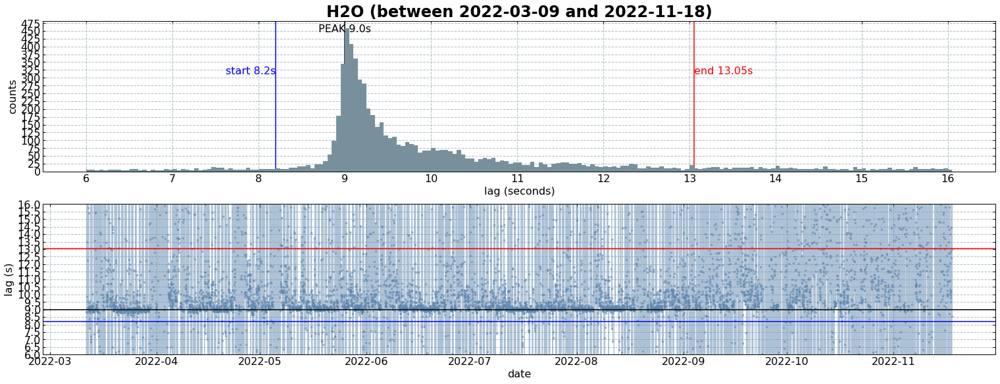

In [47]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=8.2, vline2=13.05, startbin=6, endbin=16)

### 2022_4

In [48]:
locs = (df.index.year == 2022) & ((df.index > "2022-11-18 01:00:00") & (df.index <= "2022-12-31 23:59:00"))
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

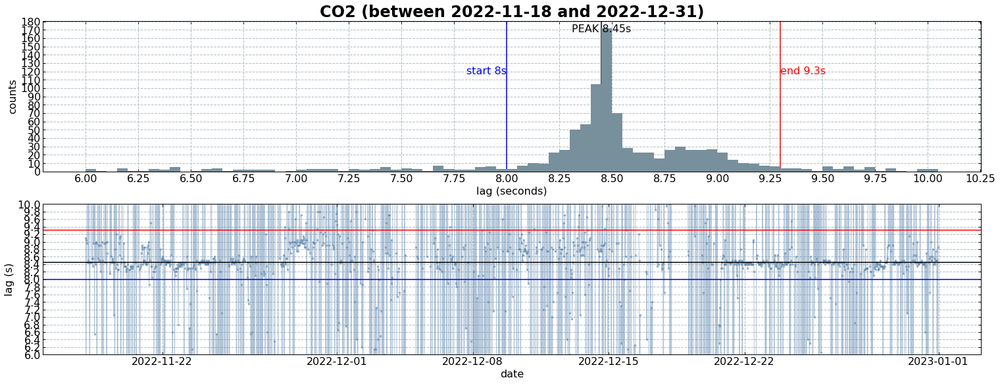

In [49]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=8, vline2=9.3, startbin=6, endbin=10)

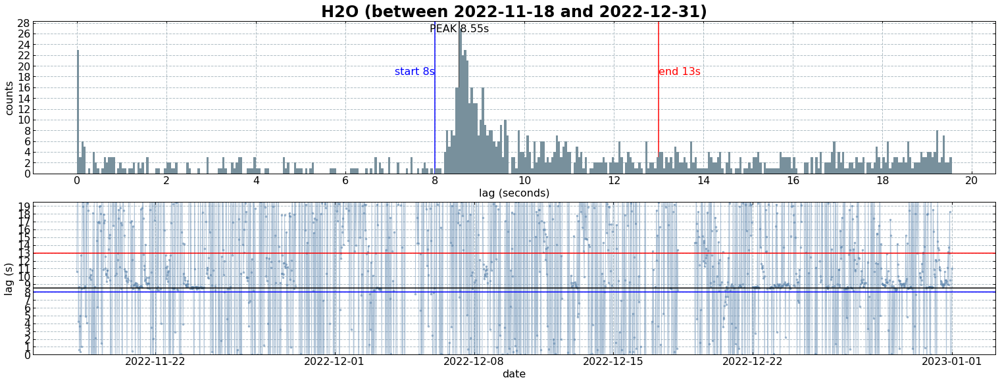

In [50]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=8, vline2=13, startbin=0, endbin=20)

## 2023_1+2

In [51]:
locs = df.index.year == 2023
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

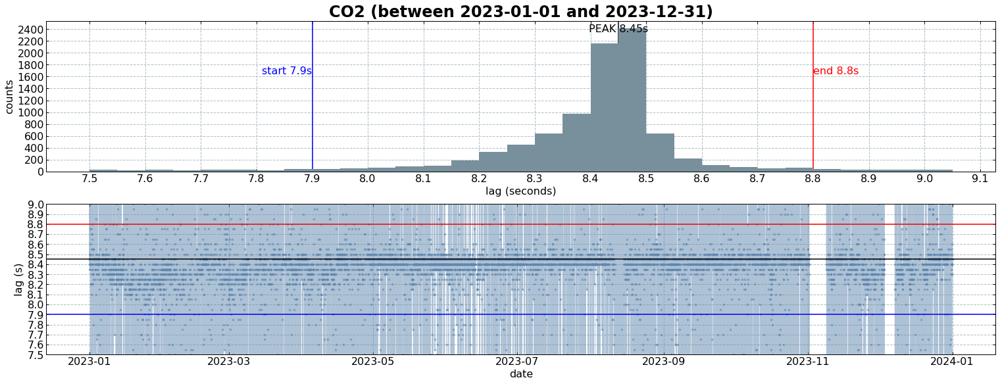

In [52]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=7.5, endbin=9)

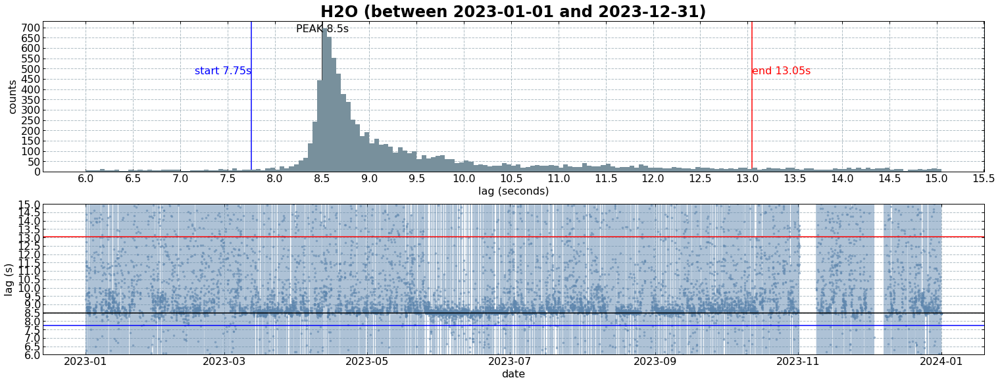

In [53]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=7.75, vline2=13.05, startbin=6, endbin=15)

## 2024_1

In [54]:
locs = df.index.year == 2024
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

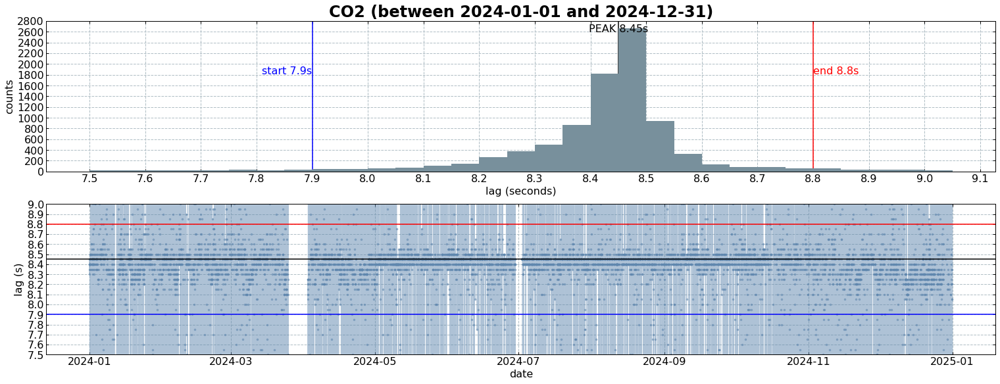

In [55]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=7.5, endbin=9)

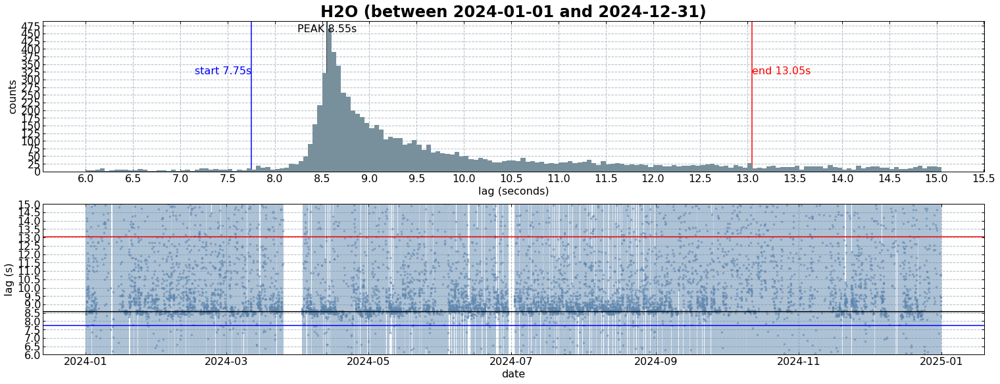

In [56]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=7.75, vline2=13.05, startbin=6, endbin=15)

## 2025_1

In [57]:
locs = df.index.year == 2025
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

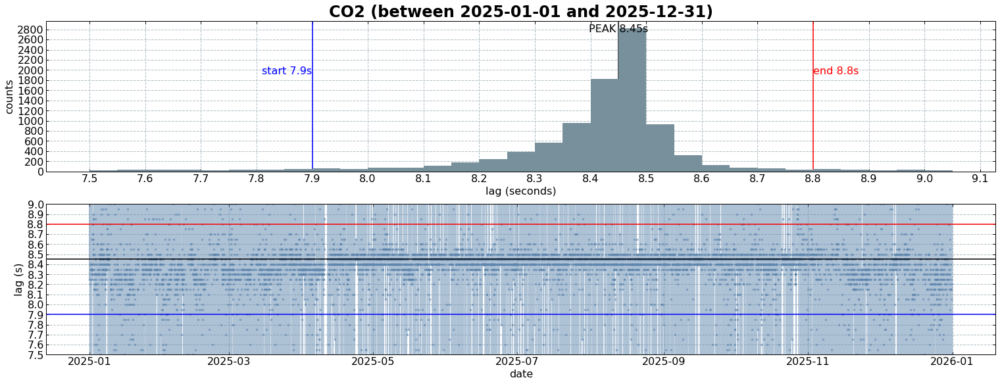

In [58]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=7.5, endbin=9)

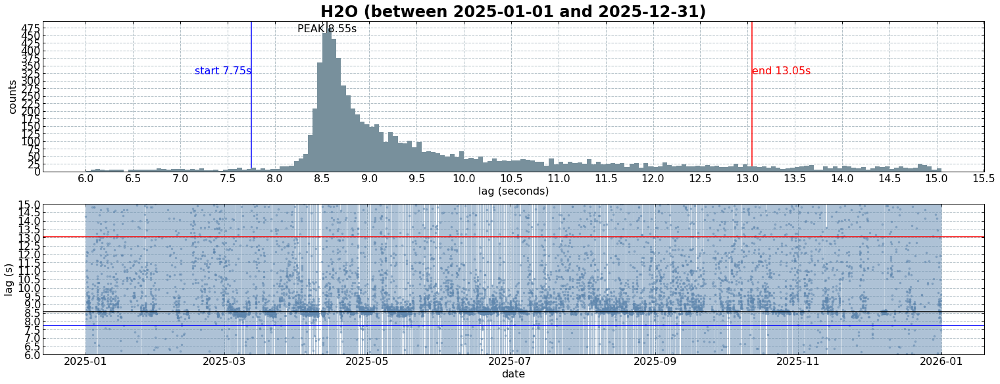

In [59]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=7.75, vline2=13.05, startbin=6, endbin=15)

## 2026_1

In [60]:
locs = df.index.year == 2026
tlag_actual = df[tlag_actual_cols][locs].copy()
first_date = tlag_actual.index[0].date()
last_date = tlag_actual.index[-1].date()

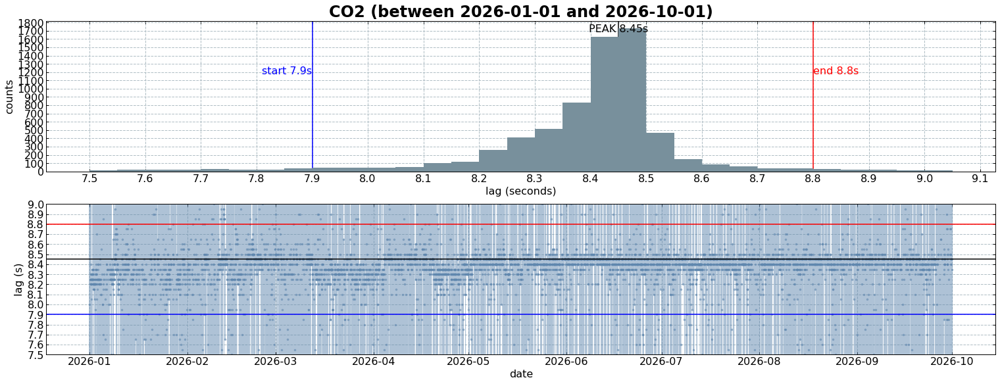

In [61]:
timelags(gascol="CO2", series=tlag_actual["CO2_TLAG_ACTUAL"], vline1=7.9, vline2=8.8, startbin=7.5, endbin=9)

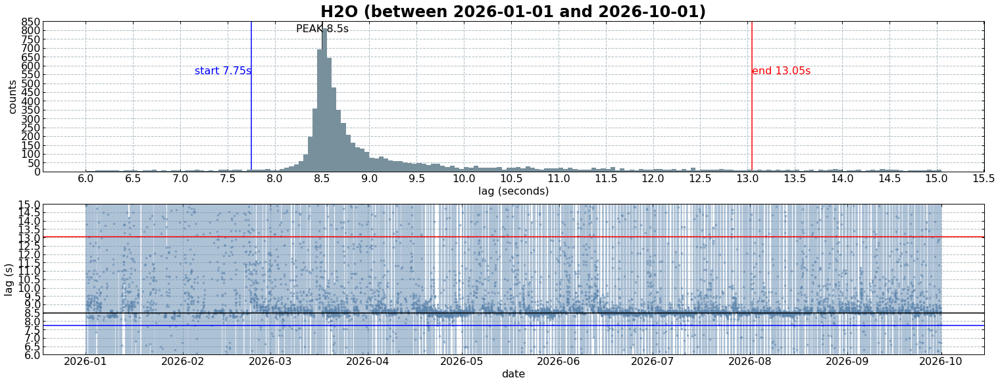

In [62]:
timelags(gascol="H2O", series=tlag_actual["H2O_TLAG_ACTUAL"], vline1=7.75, vline2=13.05, startbin=6, endbin=15)

# End of notebook.

In [63]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Finished. {dt_string}")

Finished. 2026-10-22 13:04:01
